# 02 — Experimento KAN Grid Extension con Backbone Entrenado en la Base

Diferencias vs Notebook 10 (KAN grid=7 con backbone ImageNet):
- El backbone NO se inicializa con ImageNet (`pretrained=False`).
- Se copian los pesos del ResNet18 baseline entrenado en la base de datos (`resnet18_baseline_v2.pt`, notebook 01) al backbone del hibrido.
- La KAN se entrena desde cero igual que en 10.

Objetivo: Determinar si inicializar el backbone con pesos que ya conocen los datos mejora el rendimiento de la KAN con grid=7 respecto a ImageNet. Compara:
- 1C (10): ResNet18 ImageNet + KAN [512,32,2] grid=7
- 1D (12): ResNet18 baseline-base + KAN [512,32,2] grid=7

Configuracion experimental:
- Backbone: ResNet18 entrenado en la base (checkpoint notebook 01, congelado en Fase 1)
- KAN: width=[512, 32, 2], grid=7, k=3
- Fase 1: Solo KAN (backbone congelado), 8 epocas, lr=1e-3
- Fase 2: KAN + layer4 descongelado, 10 epocas, lr_kan=5e-4, lr_backbone=1e-5

Criterios de exito:
- AUC test > 0.635
- Comparar con 1C (10) para ver si el backbone pre-entrenado en la base aporta ventaja


In [1]:
import sys, os
sys.path.insert(0, os.path.join(os.getcwd(), '..'))

import torch
import pandas as pd
import numpy as np
from torch.utils.data import DataLoader

from src.data import MammographyDataset
from src.data.preprocessing import get_train_transforms, get_val_transforms, SEED
from src.models import HybridResNetKAN
from src.models.hybrid_model import load_backbone_from_baseline
from src.training import Trainer
from src.evaluation import compute_all_metrics, compute_youden_threshold, apply_threshold, print_metrics_table

# Configuracion
BATCH_SIZE = 24
PHASE1_LR = 1e-3
PHASE2_LR_KAN = 5e-4
PHASE2_LR_BACKBONE = 1e-5
WEIGHT_DECAY = 1e-4
PHASE1_EPOCHS = 8
PHASE2_EPOCHS = 10
EARLY_STOP_PATIENCE = 4
GRID_UPDATE_ENABLED = True
RUN_LBFGS = False
KAN_WIDTH = [512, 32, 2]
KAN_GRID = 7
KAN_K = 3
MODEL_NAME = 'resnet18_kan_grid7_base'
BASELINE_CKPT = '../reports/models/resnet18_baseline_v2.pt'
OUTPUT_DIR = '../reports/models'
EXPERIMENT_DIR = '../reports/experiments'
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'

print(f'Device: {DEVICE}')
print(f'KAN width: {KAN_WIDTH}')
print(f'KAN grid: {KAN_GRID}, k: {KAN_K}')
print(f'Batch size: {BATCH_SIZE}')
print(f'Backbone: {BASELINE_CKPT}')

Device: cuda
KAN width: [512, 32, 2]
KAN grid: 7, k: 3
Batch size: 24
Backbone: ../reports/models/resnet18_baseline_v2.pt


In [2]:
# Cargar datos (manifiestos completos SIN re-dividir)
MANIFEST_TRAIN = '../src/data/processed/manifest_train.csv'
MANIFEST_VAL = '../src/data/processed/manifest_val.csv'
MANIFEST_TEST = '../src/data/processed/manifest_test.csv'

df_train = pd.read_csv(MANIFEST_TRAIN)
df_val = pd.read_csv(MANIFEST_VAL)
df_test = pd.read_csv(MANIFEST_TEST)

print(f'Train: {len(df_train)} imgs ({df_train["patient_id"].nunique()} pacientes)')
print(f'Val: {len(df_val)} imgs ({df_val["patient_id"].nunique()} pacientes)')
print(f'Test: {len(df_test)} imgs ({df_test["patient_id"].nunique()} pacientes)')

print('\nDistribucion de clases:')
for name, df in [('Train', df_train), ('Val', df_val), ('Test', df_test)]:
    counts = df['label'].value_counts().sort_index()
    total = len(df)
    print(f'  {name}: Benigno={counts.get(0, 0)} ({counts.get(0, 0)/total*100:.1f}%), Maligno={counts.get(1, 0)} ({counts.get(1, 0)/total*100:.1f}%)')

train_p = set(df_train['patient_id'])
val_p = set(df_val['patient_id'])
test_p = set(df_test['patient_id'])
print('\nVerificacion data leakage:')
print(f'  Train-Val: {len(train_p & val_p)} pacientes')
print(f'  Train-Test: {len(train_p & test_p)} pacientes')
print(f'  Val-Test: {len(val_p & test_p)} pacientes')

Train: 4278 imgs (999 pacientes)
Val: 1134 imgs (249 pacientes)
Test: 1012 imgs (318 pacientes)

Distribucion de clases:
  Train: Benigno=2439 (57.0%), Maligno=1839 (43.0%)
  Val: Benigno=631 (55.6%), Maligno=503 (44.4%)
  Test: Benigno=594 (58.7%), Maligno=418 (41.3%)

Verificacion data leakage:
  Train-Val: 0 pacientes
  Train-Test: 0 pacientes
  Val-Test: 0 pacientes


In [3]:
# Datasets y DataLoaders
train_ds = MammographyDataset(df_train, transform=get_train_transforms())
val_ds = MammographyDataset(df_val, transform=get_val_transforms())
test_ds = MammographyDataset(df_test, transform=get_val_transforms())

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, drop_last=True, num_workers=2)
val_loader = DataLoader(val_ds, batch_size=32, shuffle=False, num_workers=2)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False, num_workers=2)

class_weights = train_ds.get_class_weights()
print(f'Pesos de clase: {class_weights}')

Pesos de clase: tensor([0.4299, 0.5701])


In [4]:
# Modelo: backbone desde el baseline entrenado en la base + KAN desde cero
torch.manual_seed(SEED)
model = HybridResNetKAN(
    pretrained=False,          # NO usar ImageNet
    kan_width=KAN_WIDTH,
    kan_grid=KAN_GRID,
    kan_k=KAN_K,
    seed=SEED,
    device=DEVICE,
)
model = load_backbone_from_baseline(BASELINE_CKPT, model, device=DEVICE)
model = model.to(DEVICE)

total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Parametros totales: {total_params:,}')
print(f'Parametros entrenables (Fase 1): {trainable_params:,}')
print(f'KAN width: {model.kan_head.width}')

checkpoint directory created: ./model
saving model version 0.0
[backbone] 120 tensores copiados desde ../reports/models/resnet18_baseline_v2.pt
[backbone] no mapeados: 0 | faltantes: 0
Parametros totales: 11,480,328
Parametros entrenables (Fase 1): 263,168
KAN width: [[512, 0], [32, 0], [2, 0]]


In [5]:
# Entrenamiento en 2 fases
trainer = Trainer(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    device=DEVICE,
    class_weights=class_weights,
    output_dir=OUTPUT_DIR,
    model_name=MODEL_NAME,
)

history = trainer.train(
    phase1_epochs=PHASE1_EPOCHS,
    phase2_epochs=PHASE2_EPOCHS,
    phase1_lr=PHASE1_LR,
    phase2_lr_kan=PHASE2_LR_KAN,
    phase2_lr_backbone=PHASE2_LR_BACKBONE,
    weight_decay=WEIGHT_DECAY,
    early_stop_patience=EARLY_STOP_PATIENCE,
    grid_update_enabled=GRID_UPDATE_ENABLED,
    run_lbfgs=RUN_LBFGS,
)

best_p2 = max((h['vl_auc'] for h in history if h['phase'] == 2), default=float('nan'))
best_p1 = max((h['vl_auc'] for h in history if h['phase'] == 1), default=float('nan'))
print(f'\nMejor AUC validacion: Fase 1 = {best_p1:.4f} | Fase 2 = {best_p2:.4f}')


=== FASE 1: Entrenamiento cabezal KAN (backbone congelado) ===
[Fase 1] Backbone congelado. Solo KAN se actualiza.


  Época 01 | Loss 0.2831/0.8177 | Acc 0.8832/0.7037 | AUC 0.7675
  ✓ Checkpoint guardado (AUC=0.7675)


  Época 02 | Loss 0.2648/0.7853 | Acc 0.8869/0.7055 | AUC 0.7692
  ✓ Checkpoint guardado (AUC=0.7692)


  Época 03 | Loss 0.2527/0.8310 | Acc 0.8949/0.6922 | AUC 0.7698
  ✓ Checkpoint guardado (AUC=0.7698)


  Época 04 | Loss 0.2528/0.8932 | Acc 0.8935/0.7028 | AUC 0.7711
  ✓ Checkpoint guardado (AUC=0.7711)


  Época 05 | Loss 0.2305/0.8776 | Acc 0.9026/0.7002 | AUC 0.7720
  ✓ Checkpoint guardado (AUC=0.7720)


... (5 outputs left out)

  Época 03 | Loss 0.2097/0.9633 | Acc 0.9148/0.7002 | AUC 0.7660


  Época 04 | Loss 0.1884/0.9906 | Acc 0.9237/0.7002 | AUC 0.7647


  Época 05 | Loss 0.1861/1.0042 | Acc 0.9253/0.6949 | AUC 0.7650


  Época 06 | Loss 0.1860/0.9589 | Acc 0.9244/0.6966 | AUC 0.7638
  EarlyStopping en época 6

Historial guardado en ../reports/models\resnet18_kan_grid7_base_history.csv
Mejor AUC validación: 0.7725

Mejor AUC validacion: Fase 1 = 0.7720 | Fase 2 = 0.7725


In [6]:
# Cargar el mejor checkpoint (asegura usar el mejor de la sesion)
checkpoint_path = os.path.join(OUTPUT_DIR, f'{MODEL_NAME}.pt')
print(f'Cargando checkpoint desde: {checkpoint_path}')

torch.manual_seed(SEED)
model = HybridResNetKAN(
    pretrained=False,
    kan_width=KAN_WIDTH,
    kan_grid=KAN_GRID,
    kan_k=KAN_K,
    seed=SEED,
    device=DEVICE,
)
model = model.to(DEVICE)
model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE))
print('Checkpoint cargado exitosamente')
model.eval()

Cargando checkpoint desde: ../reports/models\resnet18_kan_grid7_base.pt
checkpoint directory created: ./model
saving model version 0.0
Checkpoint cargado exitosamente


HybridResNetKAN(
  (backbone): FeatureExtractor(
    (backbone): Sequential(
      (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
      (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (2): ReLU(inplace=True)
      (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
      (4): Sequential(
        (0): BasicBlock(
          (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
          (relu): ReLU(inplace=True)
          (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
          (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
        )
        (1): BasicBlock(
          (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bi

In [ ]:
# Evaluacion en test
all_probs, all_preds, all_labels = [], [], []
with torch.no_grad():
    for images, labels in test_loader:
        logits = model(images.to(DEVICE))
        probs = torch.softmax(logits, 1)[:, 1].cpu().numpy()
        preds = logits.argmax(1).cpu().numpy()
        all_probs.extend(probs)
        all_preds.extend(preds)
        all_labels.extend(labels.numpy())

all_probs = np.array(all_probs)
all_labels = np.array(all_labels)

# Calibracion del umbral en VALIDACION (sin fuga a prueba; auditoria 25-sep-2026)
val_probs, val_labels = [], []
with torch.no_grad():
    for images, labels in val_loader:
        logits = model(images.to(DEVICE))
        val_probs.extend(torch.softmax(logits, 1)[:, 1].cpu().numpy())
        val_labels.extend(labels.numpy())
val_probs = np.array(val_probs)
val_labels = np.array(val_labels)

all_preds_05 = (all_probs >= 0.5).astype(int)
metrics_50 = compute_all_metrics(all_labels, all_preds_05, y_prob=all_probs)
print_metrics_table(metrics_50, f'Test -- {MODEL_NAME} (umbral 0.5)')

threshold, J, fpr, tpr = compute_youden_threshold(val_labels, val_probs)
preds_youden = apply_threshold(all_probs, threshold)
metrics_y = compute_all_metrics(all_labels, preds_youden, y_prob=all_probs)
print(f'\nUmbral Youden (val): {threshold:.4f} | J={J:.4f} | TVP={tpr:.4f} | TFP={fpr:.4f}')
print_metrics_table(metrics_y, f'Test (umbral val={threshold:.4f})')

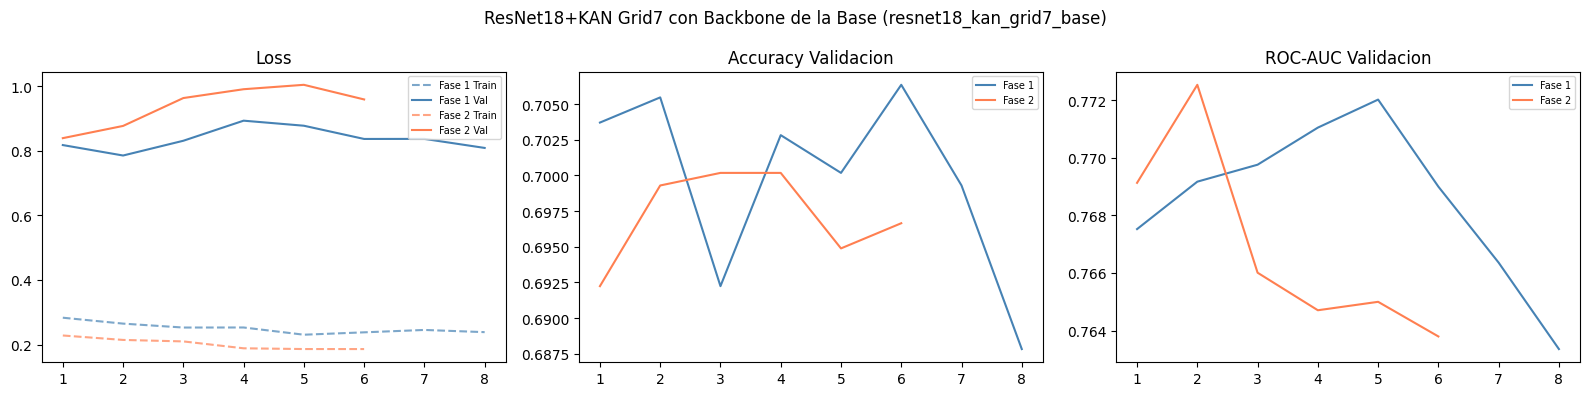

Figura guardada en ../reports/figures/12_resnet18_kan_grid7_base_training_curves.png


In [8]:
import matplotlib.pyplot as plt

# Curvas de entrenamiento por fase
df_hist = pd.DataFrame(history)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for phase_id, color in [(1, 'steelblue'), (2, 'coral')]:
    ph = df_hist[df_hist['phase'] == phase_id]
    label = f'Fase {phase_id}'
    axes[0].plot(ph['epoch'], ph['tr_loss'], '--', color=color, alpha=0.7, label=f'{label} Train')
    axes[0].plot(ph['epoch'], ph['vl_loss'], '-', color=color, label=f'{label} Val')
    axes[1].plot(ph['epoch'], ph['vl_acc'], '-', color=color, label=label)
    axes[2].plot(ph['epoch'], ph['vl_auc'], '-', color=color, label=label)

axes[0].set_title('Loss'); axes[0].legend(fontsize=7)
axes[1].set_title('Accuracy Validacion'); axes[1].legend(fontsize=7)
axes[2].set_title('ROC-AUC Validacion'); axes[2].legend(fontsize=7)
plt.suptitle(f'ResNet18+KAN Grid7 con Backbone de la Base ({MODEL_NAME})')
plt.tight_layout()
plt.savefig(f'../reports/figures/12_{MODEL_NAME}_training_curves.png', dpi=150)
plt.show()
print(f'Figura guardada en ../reports/figures/12_{MODEL_NAME}_training_curves.png')

In [ ]:
import json

os.makedirs(EXPERIMENT_DIR, exist_ok=True)
results = {
    'experimento': 'KAN Grid Extension + Backbone de la Base',
    'notebook': '12_kan_grid7_from_base.ipynb',
    'arquitectura': f'ResNet18(base) + KAN({KAN_WIDTH}) grid={KAN_GRID}',
    'backbone': 'resnet18_baseline_v2.pt (entrenado en la base)',
    'config': {
        'kan_width': KAN_WIDTH,
        'kan_grid': KAN_GRID,
        'kan_k': KAN_K,
        'batch_size': BATCH_SIZE,
        'phase1_lr': PHASE1_LR,
        'phase2_lr_kan': PHASE2_LR_KAN,
        'phase2_lr_backbone': PHASE2_LR_BACKBONE,
        'phase1_epochs': PHASE1_EPOCHS,
        'phase2_epochs': PHASE2_EPOCHS,
        'seed': SEED,
        'grid_update': GRID_UPDATE_ENABLED,
        'lbfgs': RUN_LBFGS
    },
    'metricas_umbral_05': metrics_50,
    'metricas_youden': metrics_y,
    'umbral_youden': float(threshold),
    'nota_calibracion': 'Umbral de Youden calibrado en validacion y aplicado congelado a prueba (auditoria 25-sep-2026).',
    'historial': history,
    'comparacion_con_1C': {
        '1C_backbone': 'ImageNet (notebook 10)',
        '1C_auc_test': 0.6869,
        '1C_recall_youden': 0.6818
    }
}

results_path = os.path.join(EXPERIMENT_DIR, '12_kan_grid7_from_base.json')
with open(results_path, 'w') as f:
    json.dump(results, f, indent=2, default=str)

print(f'Resultados guardados en {results_path}')
print('\n--- Resumen ---')
print(f'AUC test (0.5): {metrics_50["roc_auc"]:.4f}')
print(f'AUC test (Youden): {metrics_y["roc_auc"]:.4f}')
print(f'Recall test (Youden): {metrics_y["recall"]:.4f}')
print(f'F1 test (Youden): {metrics_y["f1"]:.4f}')
print('\nComparacion con 1C (ImageNet):')
print(f'  1C AUC test: 0.6869 | 1D AUC test: {metrics_y["roc_auc"]:.4f}')
print(f'  Diferencia: {metrics_y["roc_auc"] - 0.6869:+.4f}')